# 03 Emulated tier (E): fixed-point arithmetic and the RTL cross-check

Tier E replaces float math by what a digital implementation would do. The spec (full text: `docs/fixed_point_spec.md`, single source: the docstring of `dlnn/tiers/emulated.py`):

| step | formula | width |
|---|---|---|
| ADC | $x_q=\mathrm{clip}(\mathrm{rnd}(x/s_0),-L,L)$, $L=2^{b-1}-1$, $s_0=\text{fullscale}/L$ | $b$ bit signed (8 default) |
| ternary MAC | $\mathrm{acc}=b_q[o]+\sum_{i,k}W_{o,i,k}\,x_q[i,n-kd]$ | int32 |
| scale | $z=\mathrm{clip}((\mathrm{acc}\cdot M+2^{14})\gg15,-128,127)$ | int64 intermediate |
| tanh LUT | $v=\mathrm{LUT}[z+128]$, $\mathrm{LUT}[j]=\mathrm{rnd}(127\tanh((j-128)\cdot4/128))$ | int8 |
| per-line gain | $y=(v\,R[o]+2^{14})\gg15$ (Q.15) | int8 |
| pool | $P[o]=\sum_n y[o,n]$ | int32 |

**What is verified how.** The numpy "golden model" runs all 4000 test examples and all sweeps. The Icarus Verilog RTL (`hw/rtl/tdl_layer.v`) is compared **bit for bit** with the golden model on a subset (the first 64 examples, all 3 layers chained, plus layer 1 at ADC widths 4-10): a tier E with any mismatch would be `fallback`, not `ok`. The ADC quantiser, the pooled-sum to float conversion and the float readout are numpy post-processing in both paths.

In [1]:
import json, os, time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from dlnn.viz import nb, figures
from dlnn.viz.common import TIER_COL, MARKERS, LINESTYLES, TIER_SHORT, INK, conf_matrix

nb.setup()
run = nb.load_run()          # env DLNN_RUN, default out/modrec-w32-full (read-only; the pipeline is NOT rerun here)
cmp = run.cmp
print(f"run {run.dir.name} | model {os.path.basename(cmp['run_meta']['model_file'])} | cascade={run.cascade} | "
      f"tiers {cmp['tiers']} | n_test {cmp['tier_info']['V']['n_examples']}")
from dlnn.tiers import emulated, virtual
from dlnn.tiers.common import softmax, mean_kl
model = run.model
x_all, y_all = run.x_test, run.labels
cls = run.classes

run final-w32 | model tdlnet_modrec_w32_ternary.npz | cascade=True | tiers ['V', 'E', 'C', 'R'] | n_test 4000


### The LUT and the ADC

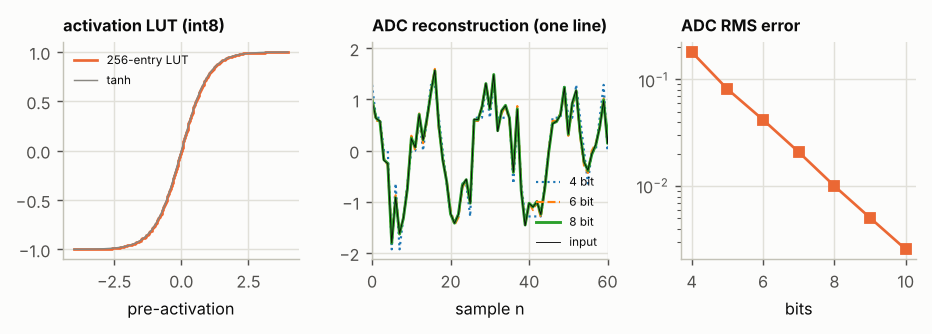

In [2]:
fig, axs = plt.subplots(1, 3, figsize=(7.2, 2.6))
j = np.arange(256)
axs[0].plot((j - 128) * 4 / 128, emulated.LUT / 127, color=TIER_COL["light"]["E"], drawstyle="steps-mid", label="256-entry LUT")
axs[0].plot((j - 128) * 4 / 128, np.tanh((j - 128) * 4 / 128), color=INK["light"]["muted"], lw=0.8, label="tanh")
axs[0].set_title("activation LUT (int8)", fontsize=9); axs[0].set_xlabel("pre-activation"); axs[0].legend(fontsize=6.5)
xs = (x_all[0] * model.input_scale)[0]
for bits, ls in ((4, ":"), (6, "--"), (8, "-")):
    q, s0 = emulated.quantize_input(xs[None, None], model.input_fullscale, bits)
    axs[1].plot(q[0, 0] * s0, ls=ls, lw=1.2 if bits < 8 else 1.6, label=f"{bits} bit")
axs[1].plot(xs, color=INK["light"]["text"], lw=0.5, label="input"); axs[1].set_title("ADC reconstruction (one line)", fontsize=9); axs[1].set_xlabel("sample n"); axs[1].set_xlim(0, 60); axs[1].legend(fontsize=6.5)
err = {b: (emulated.quantize_input(xs, model.input_fullscale, b)[0] * emulated.quantize_input(xs, model.input_fullscale, b)[1] - xs) for b in range(4, 11)}
axs[2].semilogy(list(err), [float(np.sqrt(np.mean(e ** 2))) for e in err.values()], "s-", color=TIER_COL["light"]["E"]); axs[2].set_title("ADC RMS error", fontsize=9); axs[2].set_xlabel("bits")
fig.tight_layout(); nb.show_fig(fig)

### Layer 1 in integers, one output unit, one example
The same quantities that exist as signals in the RTL.

In [3]:
EX, o = 6, 3
xq, s0 = emulated.adc_codes(model, x_all[EX:EX + 1], 8)
ly = model.layers[0]
pr = emulated.layer_params(ly, s0)
acc = np.zeros(xq.shape[2], dtype=np.int64)
for k in range(ly.W.shape[2]):
    s = k * ly.dilation
    acc[s:] += np.einsum("i,it->t", ly.W[o, :, k].astype(np.int64), xq[0, :, :xq.shape[2] - s])
acc += pr["bq"][o]
z = np.clip((acc * pr["M"] + (1 << 14)) >> 15, -128, 127)
yq = (emulated.LUT[z + 128].astype(np.int64) * pr["R"][o] + (1 << 14)) >> 15
y_gold, s_out = emulated.layer_fixed(xq, s0, ly)
y_float = virtual.layer_forward(x_all[EX:EX + 1] * model.input_scale, ly)[0, o]
n0 = 40
rows = ["| n | x_q (I) | x_q (Q) | acc (int32) | z | y_q (int8) | y_q*s_out | y float (V) |", "|---|---|---|---|---|---|---|---|"]
for n in range(n0, n0 + 8):
    rows.append(f"| {n} | {xq[0, 0, n]} | {xq[0, 1, n]} | {acc[n]} | {z[n]} | {yq[n]} | {yq[n] * s_out:+.4f} | {y_float[n]:+.4f} |")
nb.md("\n".join(rows))
print("this cell == emulated.layer_fixed (bit-exact):", bool((yq == y_gold[0, o]).all()), "| max |dequantised - float|:", float(np.abs(yq * s_out - y_float).max()))
print(f"ADC step s0 = {s0:.4f}, LUT range +-{emulated.LUT_RANGE}, M = {pr['M']}, R[o] = {pr['R'][o]} (Q.15), s_out = {s_out:.5f}")

| n | x_q (I) | x_q (Q) | acc (int32) | z | y_q (int8) | y_q*s_out | y float (V) |
|---|---|---|---|---|---|---|---|
| 40 | -10 | -6 | -79 | -62 | -122 | -0.9606 | -0.9594 |
| 41 | 11 | -14 | -110 | -87 | -126 | -0.9921 | -0.9912 |
| 42 | 1 | -21 | -112 | -88 | -126 | -0.9921 | -0.9919 |
| 43 | 4 | -39 | -28 | -22 | -76 | -0.5984 | -0.6090 |
| 44 | -3 | -13 | -55 | -43 | -111 | -0.8740 | -0.8764 |
| 45 | -31 | -43 | -3 | -2 | -8 | -0.0630 | -0.0323 |
| 46 | 17 | -37 | -149 | -117 | -127 | -1.0000 | -0.9988 |
| 47 | -9 | -45 | -47 | -37 | -104 | -0.8189 | -0.8252 |

this cell == emulated.layer_fixed (bit-exact): True | max |dequantised - float|: 0.07255803318474235
ADC step s0 = 0.0354, LUT range +-4.0, M = 25829, R[o] = 32768 (Q.15), s_out = 0.00787


### ADC-bits sweep, live on a subset (compare with the stored full-set sweep)

7 ADC widths on 500 examples: 4.1 s


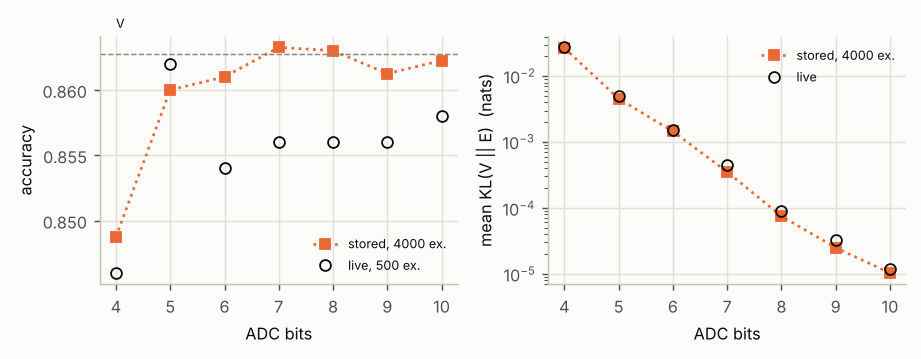

| ADC bits | accuracy (live) | top-1 agreement with V | mean KL(V\|\|E) |
|---|---|---|---|
| 4 | 0.8460 | 0.9320 | 2.74e-02 |
| 5 | 0.8620 | 0.9840 | 4.97e-03 |
| 6 | 0.8540 | 0.9960 | 1.52e-03 |
| 7 | 0.8560 | 0.9900 | 4.54e-04 |
| 8 | 0.8560 | 0.9980 | 9.06e-05 |
| 9 | 0.8560 | 0.9980 | 3.25e-05 |
| 10 | 0.8580 | 1.0000 | 1.19e-05 |

In [4]:
N = nb.n_subset(500)
xs_, ys_ = x_all[:N], y_all[:N]
ref = virtual.forward(model, xs_)["out"]
p_ref = softmax(ref)
rows = []
t0 = time.time()
for bits in range(4, 11):
    o_ = emulated.forward(model, xs_, adc_bits=bits)["out"]
    p_ = softmax(o_)
    rows.append((bits, float((o_.argmax(1) == ys_).mean()), float((o_.argmax(1) == ref.argmax(1)).mean()), mean_kl(p_ref, p_)))
print(f"7 ADC widths on {N} examples: {time.time() - t0:.1f} s")
sw = cmp["sweeps"]["adc_bits"]["E"]
fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.8))
bits_ = [r[0] for r in rows]
axs[0].plot(sw["values"], sw["accuracy"], "s:", color=TIER_COL["light"]["E"], label="stored, 4000 ex.")
axs[0].plot(bits_, [r[1] for r in rows], "o", mfc="none", mec=INK["light"]["text"], label=f"live, {N} ex.")
axs[0].axhline(cmp["metric_matrix"]["accuracy"]["V"], color=INK["light"]["muted"], ls="--", lw=0.8); axs[0].text(4, cmp["metric_matrix"]["accuracy"]["V"] + 0.002, "V", fontsize=7)
axs[0].set_xlabel("ADC bits"); axs[0].set_ylabel("accuracy"); axs[0].legend(fontsize=7)
axs[1].semilogy(sw["values"], np.maximum(sw["mean_kl"], 1e-7), "s:", color=TIER_COL["light"]["E"], label="stored, 4000 ex.")
axs[1].semilogy(bits_, [max(r[3], 1e-7) for r in rows], "o", mfc="none", mec=INK["light"]["text"], label="live")
axs[1].set_xlabel("ADC bits"); axs[1].set_ylabel("mean KL(V || E)  (nats)"); axs[1].legend(fontsize=7)
fig.tight_layout(); nb.show_fig(fig)
nb.md("| ADC bits | accuracy (live) | top-1 agreement with V | mean KL(V\\|\\|E) |\n|---|---|---|---|\n" + "\n".join(f"| {b} | {a:.4f} | {g:.4f} | {k:.2e} |" for b, a, g, k in rows))

### RTL vs numpy: bit-exact check (live, small count)
If `iverilog` is missing this cell reports it and continues (the tier would then be labelled `fallback: bit-true model (no RTL)`).

In [5]:
info = emulated.rtl_info()
print("iverilog:", info)
if info["available"]:
    t0 = time.time()
    res = emulated.rtl_crosscheck(model, x_all[:8], {"rtl_examples": 8, "rtl_adc_check": False})
    print(f"live RTL run: {res['examples']} examples x first {res['T']} of {res['T_full']} time steps, tool {res['rtl_tool']}, {time.time() - t0:.0f} s")
    rows = ["| layer | values compared | mismatches | pooled sums compared | pooled mismatches |", "|---|---|---|---|---|"]
    for d_ in res["layers"]:
        rows.append(f"| {d_['layer']} | {d_['values_compared']} | {d_['mismatches']} | {d_['pool_compared']} | {d_['pool_mismatches']} |")
    nb.md("\n".join(rows))
    print(f"TOTAL: {res['values_compared']} values compared, {res['mismatches']} mismatches; RTL-driven readout identical to golden: {res['readout_identical']}")
else:
    print("iverilog not available: skipping the live RTL run (see the stored result below).")
stored = json.loads((run.dir / "tiers" / "E_rtl.json").read_text()) if (run.dir / "tiers" / "E_rtl.json").exists() else None
if stored and stored.get("ran"):
    print(f"\nSTORED (the pipeline run): {stored['examples']} examples, {stored['values_compared']} values, {stored['mismatches']} mismatches; "
          f"ADC widths 4-10 on layer 1: {stored['adc_values_compared']} values, {stored['adc_mismatches']} mismatches; readout identical: {stored['readout_identical']}")

iverilog: {'available': True, 'version': '12.0', 'reason': ''}


live RTL run: 8 examples x first 68 of 128 time steps, tool iverilog 12.0, 17 s


| layer | values compared | mismatches | pooled sums compared | pooled mismatches |
|---|---|---|---|---|
| 1 | 17408 | 0 | 256 | 0 |
| 2 | 17408 | 0 | 256 | 0 |
| 3 | 17408 | 0 | 256 | 0 |

TOTAL: 52992 values compared, 0 mismatches; RTL-driven readout identical to golden: True

STORED (the pipeline run): 64 examples, 202752 values, 0 mismatches; ADC widths 4-10 on layer 1: 118272 values, 0 mismatches; readout identical: True


### Mismatch accounting: how E differs from V on the whole test set

E vs V: 11 of 4000 examples change the top-1 class (agreement 0.99725); accuracy V 0.86275 vs E 0.86300
V top-1 minus top-2 probability on the disagreeing examples: [0.009999999776482582, 0.0, 0.009999999776482582, 0.0, 0.009999999776482582, 0.009999999776482582, 0.009999999776482582, 0.0, 0.009999999776482582, 0.009999999776482582, 0.019999999552965164]
median over all examples: 0.98 -> the flips happen on near-ties, as expected from 8-bit rounding


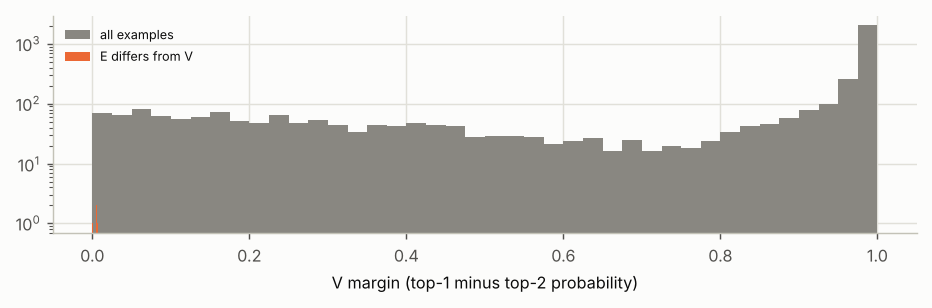

| layer | NMSE of E layer output vs V (first 16 examples) |
|---|---|
| 1 | 1.57e-04 |
| 2 | 1.89e-04 |
| 3 | 3.47e-04 |

In [6]:
pv, pe = run.res["V"].arrays["pred"], run.res["E"].arrays["pred"]
dis = np.where(pv != pe)[0]
print(f"E vs V: {len(dis)} of {len(pv)} examples change the top-1 class (agreement {1 - len(dis) / len(pv):.5f}); accuracy V {float((pv == y_all).mean()):.5f} vs E {float((pe == y_all).mean()):.5f}")
Pv = run.res["V"].arrays["probs"]
margin = np.sort(Pv, axis=1)
gap = margin[:, -1] - margin[:, -2]
print("V top-1 minus top-2 probability on the disagreeing examples:", np.round(gap[dis], 2).tolist())
print("median over all examples:", round(float(np.median(gap)), 2), "-> the flips happen on near-ties, as expected from 8-bit rounding")
fig, ax = plt.subplots(figsize=(7.2, 2.4))
ax.hist(gap, bins=40, color=INK["light"]["muted"], label="all examples"); ax.hist(gap[dis], bins=40, color=TIER_COL["light"]["E"], label="E differs from V")
ax.set_yscale("log"); ax.set_xlabel("V margin (top-1 minus top-2 probability)"); ax.legend(fontsize=7); fig.tight_layout(); nb.show_fig(fig)
rows = ["| layer | NMSE of E layer output vs V (first 16 examples) |", "|---|---|"]
for l in range(3):
    a, b = run.trace("V", l), run.trace("E", l)
    rows.append(f"| {l + 1} | {np.mean((a - b) ** 2) / np.var(a):.2e} |")
nb.md("\n".join(rows))

**Takeaways.** 8-bit fixed point is nearly free (top-1 agreement with V 0.9972, accuracy unchanged); the accuracy only starts to drop below 5 ADC bits. The RTL equals the numpy golden model bit for bit on the checked subset. **Not covered by E:** every analog effect (loss, dispersion, noise, coupler errors), the ADC quantiser itself in hardware, and the float readout; the RTL has not been run on the full 4000 examples.